# House Price Prediction Using Linear Regression and Polynomial Regression

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Dhinesh8023/House-Price-Prediction-ML/blob/main/house_price_prediction.ipynb)
![Python](https://img.shields.io/badge/Python-3.9%20%7C%203.10%20%7C%203.11%20%7C%203.12%20%7C%203.14-3776AB?logo=python&logoColor=white)
![Scikit-Learn](https://img.shields.io/badge/scikit--learn-F7931E?logo=scikit-learn&logoColor=white)
![Jupyter](https://img.shields.io/badge/Jupyter-Notebook-F37626?logo=jupyter&logoColor=white)
![License](https://img.shields.io/badge/License-MIT-green.svg)

---
**Author:** Dhinesh8023  
**Project:** End-to-End Machine Learning Regression Pipeline  
**Dataset:** California Housing Dataset (`scikit-learn`)  
**Domain:** Predictive Real Estate Analytics & Applied Machine Learning

## 2. Introduction

Predicting real estate prices is one of the classic and most practically relevant regression problems in Machine Learning. Real estate valuation informs home buyers, financial institutions issuing mortgages, urban planners, and tax assessment bodies. 

Accurately estimating property values requires learning the underlying relationship between geographic factors, physical house properties, demographic density, and market economics. While baseline Multiple Linear Regression assumes strict additive linear relationships between features and the target price, real estate markets exhibit prominent non-linear interactions (e.g., location synergy, square-footage compounding, and income thresholds).

In this project, we implement and rigorously benchmark two fundamental regression algorithms:
1. **Multiple Linear Regression**: A linear baseline establishing first-order relationships.
2. **Polynomial Regression (Degree 2)**: A non-linear extension introducing quadratic terms and interaction features to capture complex real-world pricing dynamics.

## 3. Problem Statement

Given a set of eight continuous attributes describing California census block groups—including median resident income, median house age, room averages, population density, and geographic coordinates—the objective is to build, evaluate, and compare Machine Learning regression models that accurately predict the **median house value (`MedHouseVal`)** of each block group.

### Core Challenges:
- **Spatial Non-Linearity**: Housing prices in California do not increase linearly with latitude and longitude; coastal proximity creates high-value pockets surrounded by lower-value inland regions.
- **Feature Interactions**: Income and room counts compound each other; high income coupled with larger houses increases property value at an accelerating rate.
- **Extreme Outliers & Capping**: Census datasets contain capped values (e.g., maximum recorded house values of $500,000) and localized population outliers that test model robustness.

## 4. Project Objectives

1. **Dataset Ingestion & Exploration**: Load the California Housing dataset using `sklearn.datasets.fetch_california_housing` and perform exploratory data analysis (EDA).
2. **Data Preprocessing**: Verify data integrity (missing values), separate features and target, perform an 80/20 train-test split (`random_state=42`), and apply feature standardization using `StandardScaler`.
3. **Model Development**:
   - Train a standard **Multiple Linear Regression** model.
   - Expand the feature space using **PolynomialFeatures (Degree 2)** and train a **Polynomial Regression** model.
4. **Model Evaluation**: Compute and contrast four standard regression evaluation metrics:
   - Mean Absolute Error (**MAE**)
   - Mean Squared Error (**MSE**)
   - Root Mean Squared Error (**RMSE**)
   - Coefficient of Determination (**$R^2$ Score**)
5. **Visual Diagnostics**:
   - Actual vs. Predicted scatter plots with identity line ($y = x$).
   - Detailed model prediction visualizations.
   - Metric comparison bar charts.
   - Residual distribution and homoscedasticity diagnostics.
6. **Analytical Insights & Academic Discussion**: Explain why Polynomial Regression outperforms Linear Regression and outline practical limitations.

## 5. Dataset Description

The **California Housing Dataset** was originally derived from the 1990 U.S. Census. It consists of **20,640 records (districts/block groups)** with **8 continuous input features** and **1 continuous target variable**.

### Feature Glossary (Simple English):
| Feature Name | Description | Units / Scale |
| :--- | :--- | :--- |
| `MedInc` | Median income in block group | Tens of thousands of USD ($10,000s) |
| `HouseAge` | Median age of houses in block group | Years |
| `AveRooms` | Average number of rooms per household | Count |
| `AveBedrms` | Average number of bedrooms per household | Count |
| `Population` | Total population residing in the block group | Count |
| `AveOccup` | Average number of household members | Occupants per household |
| `Latitude` | Latitude coordinate of the block group | Degrees North |
| `Longitude` | Longitude coordinate of the block group | Degrees West |
| **`MedHouseVal`** | **Target Variable**: Median house value | Hundreds of thousands of USD ($100,000s) |

> **Note on Target Variable**: A target value of `2.0` represents a median home value of **$200,000**. The maximum recorded value is capped at `5.00001` ($500,000+).

## 6. Import Required Libraries

We import essential Python libraries for data manipulation (`pandas`, `numpy`), scientific modeling (`scikit-learn`), and professional data visualization (`matplotlib`, `seaborn`).

In [1]:
# Core numerical and tabular computing
import os
import sys
import numpy as np
import pandas as pd

# Statistical data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn tools for datasets, preprocessing, modeling, and evaluation
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Set professional plotting aesthetics
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 120

print(f"NumPy version        : {np.__version__}")
print(f"Pandas version       : {pd.__version__}")
import sklearn
print(f"Scikit-Learn version : {sklearn.__version__}")

NumPy version        : 2.4.6
Pandas version       : 3.1.0
Scikit-Learn version : 1.9.1


## 7. Dataset Loading

We fetch the California Housing dataset using `sklearn.datasets.fetch_california_housing(as_frame=True)` and convert it into a Pandas DataFrame. We inspect the dataset dimensions, column names, target name, and view the first 5 records.

In [2]:
# Load California Housing dataset
# Resilient loader: fallback to local cache directory if write access to default home is restricted
try:
    housing = fetch_california_housing(as_frame=True)
except Exception:
    local_data_dir = os.path.join(os.getcwd(), "scikit_learn_data")
    alt_dir = r"C:\Users\jsury\.gemini\antigravity\scratch\scikit_learn_data"
    data_dir = local_data_dir if os.path.exists(local_data_dir) else alt_dir
    housing = fetch_california_housing(data_home=data_dir, as_frame=True)

df = housing.frame

print("=" * 60)
print(f"Dataset Dimensions : {df.shape[0]} rows x {df.shape[1]} columns")
print(f"Feature Names      : {list(housing.feature_names)}")
print(f"Target Variable    : {housing.target_names[0]} (MedHouseVal)")
print("=" * 60)

# Display the first 5 records
print("\nFirst 5 Records:")
print(df.head().to_string())

Dataset Dimensions : 20640 rows x 9 columns
Feature Names      : ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Target Variable    : MedHouseVal (MedHouseVal)

First 5 Records:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  Longitude  MedHouseVal
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88    -122.23        4.526
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86    -122.22        3.585
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85    -122.24        3.521
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85    -122.25        3.413
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85    -122.25        3.422


## 8. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand statistical distributions, detect anomalies, verify data completeness, and assess correlation with the target variable.

In [3]:
# Statistical summary of numerical features
print("Statistical Summary of Dataset:")
print(df.describe().round(3).to_string())

Statistical Summary of Dataset:
          MedInc   HouseAge   AveRooms  AveBedrms  Population   AveOccup   Latitude  Longitude  MedHouseVal
count  20640.000  20640.000  20640.000  20640.000   20640.000  20640.000  20640.000  20640.000    20640.000
mean       3.871     28.639      5.429      1.097    1425.477      3.071     35.632   -119.570        2.069
std        1.900     12.586      2.474      0.474    1132.462     10.386      2.136      2.004        1.154
min        0.500      1.000      0.846      0.333       3.000      0.692     32.540   -124.350        0.150
25%        2.563     18.000      4.441      1.006     787.000      2.430     33.930   -121.800        1.196
50%        3.535     29.000      5.229      1.049    1166.000      2.818     34.260   -118.490        1.797
75%        4.743     37.000      6.052      1.100    1725.000      3.282     37.710   -118.010        2.647
max       15.000     52.000    141.909     34.067   35682.000   1243.333     41.950   -114.310        5.

In [4]:
# Check for missing values in all columns
missing_values = df.isnull().sum()
print("Missing Values per Column:")
print(missing_values.to_string())
print(f"\nTotal Missing Values in Dataset: {missing_values.sum()} (Clean dataset)")

Missing Values per Column:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0

Total Missing Values in Dataset: 0 (Clean dataset)


Correlation with Target Variable (MedHouseVal):
MedHouseVal    1.0000
MedInc         0.6881
AveRooms       0.1519
HouseAge       0.1056
AveOccup      -0.0237
Population    -0.0246
Longitude     -0.0460
AveBedrms     -0.0467
Latitude      -0.1442


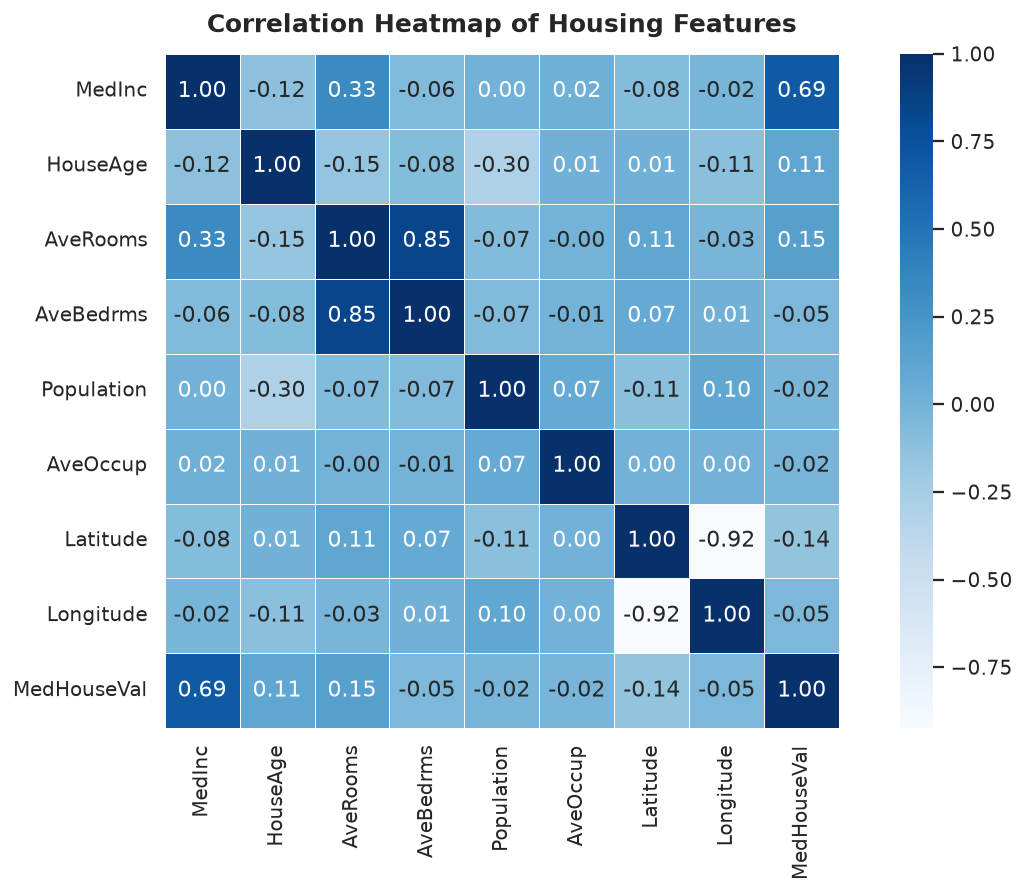

In [5]:
# Correlation matrix with target variable
corr_matrix = df.corr()
target_corr = corr_matrix["MedHouseVal"].sort_values(ascending=False)

print("Correlation with Target Variable (MedHouseVal):")
print(target_corr.round(4).to_string())

# Plot Correlation Heatmap
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="Blues", cbar=True, square=True, linewidths=0.5, ax=ax)
ax.set_title("Correlation Heatmap of Housing Features", fontsize=14, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

## 9. Data Preprocessing

Before training our machine learning models, we perform the following preprocessing steps:
1. **Feature-Target Separation**: Separate predictor variables ($X$) from the response variable ($y = \text{MedHouseVal}$).
2. **Standardization (`StandardScaler`)**: Transform input features to have zero mean ($\mu = 0$) and unit variance ($\sigma = 1$). Standardization prevents features with naturally large ranges (such as `Population` or `AveRooms`) from disproportionately dominating coefficient weights during optimization.

In [6]:
# Separate features (X) and target variable (y)
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

print(f"Feature matrix X shape: {X.shape}")
print(f"Target vector y shape  : {y.shape}")

Feature matrix X shape: (20640, 8)
Target vector y shape  : (20640,)


## 10. Train-Test Split

We split the dataset into **80% training data** and **20% testing data** using `train_test_split`. We set `random_state=42` to guarantee exact reproducibility of our results across runs.

> **Data Leakage Prevention**: We fit the `StandardScaler` **exclusively on the training data (`X_train`)** and then apply `.transform()` to `X_test`. This ensures no information from the test set leaks into our training pipeline.

In [7]:
# 80% Training and 20% Testing split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Training set: {X_train.shape[0]} samples ({X_train.shape[0]/len(df):.0%})")
print(f"Testing set : {X_test.shape[0]} samples ({X_test.shape[0]/len(df):.0%})")

# Feature Standardization using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nFeature Scaling Completed:")
print(f"X_train_scaled Mean : {X_train_scaled.mean():.4f} (approx 0)")
print(f"X_train_scaled Std  : {X_train_scaled.std():.4f} (approx 1)")

Training set: 16512 samples (80%)
Testing set : 4128 samples (20%)

Feature Scaling Completed:
X_train_scaled Mean : 0.0000 (approx 0)
X_train_scaled Std  : 1.0000 (approx 1)


## 11. Linear Regression Model

**Multiple Linear Regression** models the target variable $y$ as a linear combination of input features:

$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_p x_p$$

Where:
- $\beta_0$ is the intercept term.
- $\beta_1, \dots, \beta_p$ are learned regression coefficients representing the change in price per unit increase in the corresponding standardized feature.

In [8]:
# Initialize and train Multiple Linear Regression model
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

# Inspect model parameters
print("Linear Regression Model Trained Successfully!")
print(f"Intercept (beta_0): {lr_model.intercept_:.4f}")
print("\nLearned Feature Coefficients:")
coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient (beta)": lr_model.coef_
}).sort_values(by="Coefficient (beta)", ascending=False)

print(coef_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

Linear Regression Model Trained Successfully!
Intercept (beta_0): 2.0719

Learned Feature Coefficients:
   Feature  Coefficient (beta)
    MedInc              0.8544
 AveBedrms              0.3393
  HouseAge              0.1225
Population             -0.0023
  AveOccup             -0.0408
  AveRooms             -0.2944
 Longitude             -0.8698
  Latitude             -0.8969


## 12. Polynomial Regression Model

**Polynomial Regression** enhances the linear model by transforming the feature matrix into polynomial combinations of degree $d = 2$:

$$\hat{y} = \beta_0 + \sum_{i=1}^p \beta_i x_i + \sum_{i=1}^p \beta_{ii} x_i^2 + \sum_{i=1}^p \sum_{j > i}^p \beta_{ij} x_i x_j$$

This transformation allows the model to capture:
1. **Quadratic curvature** ($x_i^2$): diminishing or accelerating returns (e.g., house age depreciation curves).
2. **Interaction terms** ($x_i x_j$): synergistic relationships (e.g., `MedInc` $\times$ `AveRooms`, or `Latitude` $\times$ `Longitude` representing location hotspots).

In [9]:
# Create degree-2 Polynomial Features transformer
poly = PolynomialFeatures(degree=2, include_bias=False)

# Transform training and testing feature sets
X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

print(f"Original Feature Count   : {X_train_scaled.shape[1]}")
print(f"Polynomial Feature Count : {X_train_poly.shape[1]} (8 linear + 8 quadratic + 28 interaction terms)")

# Train Linear Regression on transformed polynomial feature matrix
poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)

print("\nPolynomial Regression Model Trained Successfully!")
print(f"Intercept: {poly_model.intercept_:.4f}")
print(f"Number of Learned Parameters: {len(poly_model.coef_) + 1}")

Original Feature Count   : 8
Polynomial Feature Count : 44 (8 linear + 8 quadratic + 28 interaction terms)

Polynomial Regression Model Trained Successfully!
Intercept: 1.9566
Number of Learned Parameters: 45


## 13. House Price Predictions

We now generate predictions on the unseen testing set (`X_test`) using both the Linear Regression and Polynomial Regression models.

In [10]:
# Generate predictions for both models
y_pred_lr = lr_model.predict(X_test_scaled)
y_pred_poly = poly_model.predict(X_test_poly)

# Create a comparison dataframe of first 10 testing records
predictions_preview = pd.DataFrame({
    "Actual Price ($100k)": y_test.iloc[:10].values,
    "LR Predicted": y_pred_lr[:10],
    "Poly Predicted": y_pred_poly[:10],
    "LR Abs Error": np.abs(y_test.iloc[:10].values - y_pred_lr[:10]),
    "Poly Abs Error": np.abs(y_test.iloc[:10].values - y_pred_poly[:10])
})

print("Sample Predictions Comparison (First 10 Test Districts):")
print(predictions_preview.round(4).to_string(index=False))

Sample Predictions Comparison (First 10 Test Districts):
 Actual Price ($100k)  LR Predicted  Poly Predicted  LR Abs Error  Poly Abs Error
                0.477        0.7191          0.5540        0.2421          0.0770
                0.458        1.7640          1.7512        1.3060          1.2932
                5.000        2.7097          3.4924        2.2904          1.5076
                2.186        2.8389          2.8497        0.6529          0.6637
                2.780        2.6047          2.7624        0.1753          0.0176
                1.587        2.0118          1.9135        0.4248          0.3265
                1.982        2.6455          2.6648        0.6635          0.6828
                1.575        2.1688          2.0154        0.5938          0.4404
                3.400        2.7407          2.8938        0.6593          0.5062
                4.466        3.9156          3.9675        0.5504          0.4985


## 14. Model Evaluation

To evaluate model performance, we compute four standard regression metrics:

1. **Mean Absolute Error (MAE)**:
   $$\text{MAE} = \frac{1}{n} \sum_{i=1}^n |y_i - \hat{y}_i|$$
   - **Simple English**: The average dollar difference between actual and predicted prices. It treats all errors proportionally without heavily punishing large errors.

2. **Mean Squared Error (MSE)**:
   $$\text{MSE} = \frac{1}{n} \sum_{i=1}^n (y_i - \hat{y}_i)^2$$
   - **Simple English**: The average of the squared errors. Squaring penalizes large mistakes much more harshly than small ones.

3. **Root Mean Squared Error (RMSE)**:
   $$\text{RMSE} = \sqrt{\text{MSE}}$$
   - **Simple English**: The square root of MSE, bringing the error back into the same units as the target variable (hundreds of thousands of dollars).

4. **Coefficient of Determination ($R^2$ Score)**:
   $$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$
   - **Simple English**: The percentage of price variation explained by our model's features (0% = baseline mean predictor, 100% = flawless prediction).

In [11]:
# Calculate evaluation metrics for Linear Regression
mae_lr = mean_absolute_error(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test, y_pred_lr)

# Calculate evaluation metrics for Polynomial Regression
mae_poly = mean_absolute_error(y_test, y_pred_poly)
mse_poly = mean_squared_error(y_test, y_pred_poly)
rmse_poly = np.sqrt(mse_poly)
r2_poly = r2_score(y_test, y_pred_poly)

# Compile results into a structured comparison table
metrics_comparison = pd.DataFrame({
    "Evaluation Metric": ["Mean Absolute Error (MAE)", "Mean Squared Error (MSE)", "Root Mean Squared Error (RMSE)", "R² Score (Variance Explained)"],
    "Linear Regression": [mae_lr, mse_lr, rmse_lr, r2_lr],
    "Polynomial Regression (Deg 2)": [mae_poly, mse_poly, rmse_poly, r2_poly],
    "Improvement (%)": [
        ((mae_lr - mae_poly) / mae_lr) * 100,
        ((mse_lr - mse_poly) / mse_lr) * 100,
        ((rmse_lr - rmse_poly) / rmse_lr) * 100,
        ((r2_poly - r2_lr) / r2_lr) * 100
    ]
})

print("=" * 75)
print("FINAL MODEL EVALUATION COMPARISON TABLE")
print("=" * 75)
print(metrics_comparison.round(4).to_string(index=False))

FINAL MODEL EVALUATION COMPARISON TABLE
             Evaluation Metric  Linear Regression  Polynomial Regression (Deg 2)  Improvement (%)
     Mean Absolute Error (MAE)             0.5332                         0.4670          12.4155
      Mean Squared Error (MSE)             0.5559                         0.4643          16.4762
Root Mean Squared Error (RMSE)             0.7456                         0.6814           8.6087
 R² Score (Variance Explained)             0.5758                         0.6457          12.1389


## 15. Actual vs Predicted Visualization

We generate scatter plots comparing predicted house prices against actual prices for both models. 
- The **red dashed diagonal line ($y = x$)** represents perfect prediction where predicted price equals actual price.
- Points falling closer to the red line indicate accurate predictions.
- Horizontal bands near $y = 5.0$ reveal the dataset's artificial price ceiling cap.

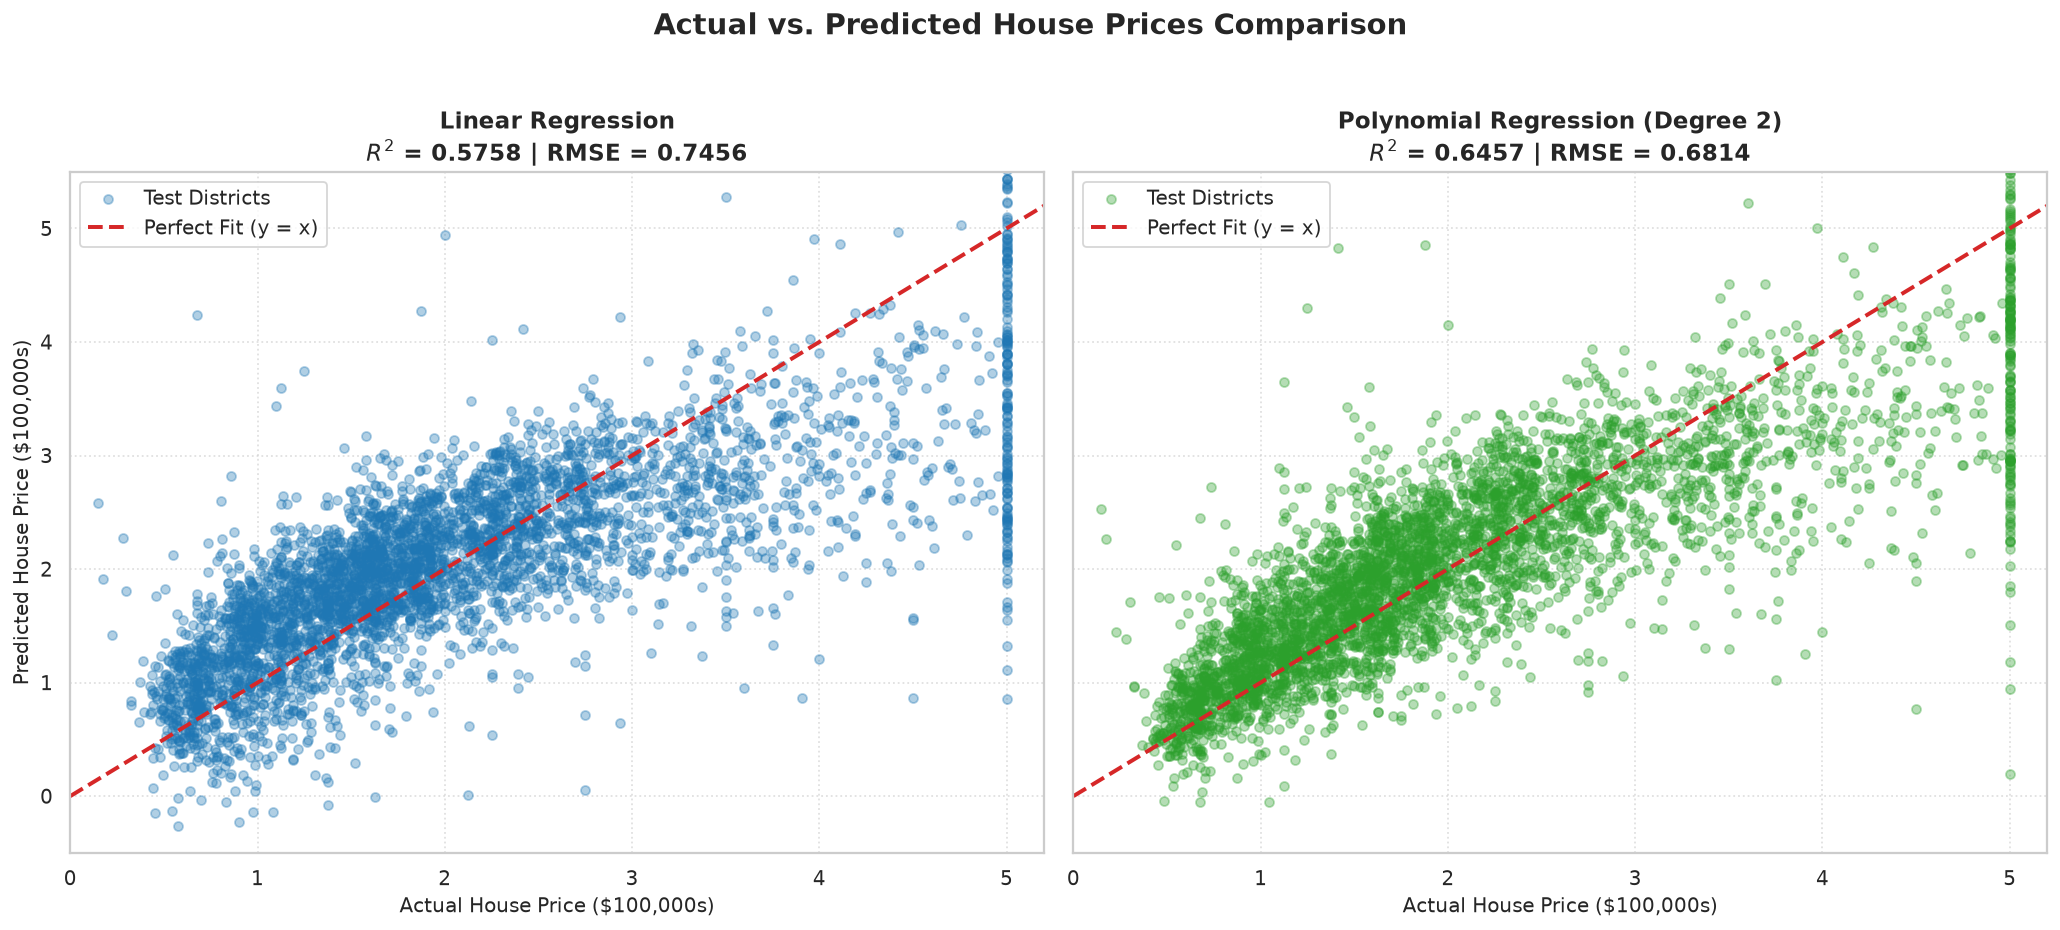

In [12]:
# Figure 1: Actual vs Predicted Comparison Subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)

# Linear Regression Plot
axes[0].scatter(y_test, y_pred_lr, alpha=0.35, color="#1f77b4", s=25, label="Test Districts")
axes[0].plot([0, 5.2], [0, 5.2], color="#d62728", linestyle="--", linewidth=2.2, label="Perfect Fit (y = x)")
axes[0].set_title(f"Linear Regression\n$R^2$ = {r2_lr:.4f} | RMSE = {rmse_lr:.4f}", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Actual House Price ($100,000s)", fontsize=11)
axes[0].set_ylabel("Predicted House Price ($100,000s)", fontsize=11)
axes[0].set_xlim(0, 5.2)
axes[0].set_ylim(-0.5, 5.5)
axes[0].grid(True, linestyle=":", alpha=0.6)
axes[0].legend(loc="upper left")

# Polynomial Regression Plot
axes[1].scatter(y_test, y_pred_poly, alpha=0.35, color="#2ca02c", s=25, label="Test Districts")
axes[1].plot([0, 5.2], [0, 5.2], color="#d62728", linestyle="--", linewidth=2.2, label="Perfect Fit (y = x)")
axes[1].set_title(f"Polynomial Regression (Degree 2)\n$R^2$ = {r2_poly:.4f} | RMSE = {rmse_poly:.4f}", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Actual House Price ($100,000s)", fontsize=11)
axes[1].set_xlim(0, 5.2)
axes[1].set_ylim(-0.5, 5.5)
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend(loc="upper left")

fig.suptitle("Actual vs. Predicted House Prices Comparison", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

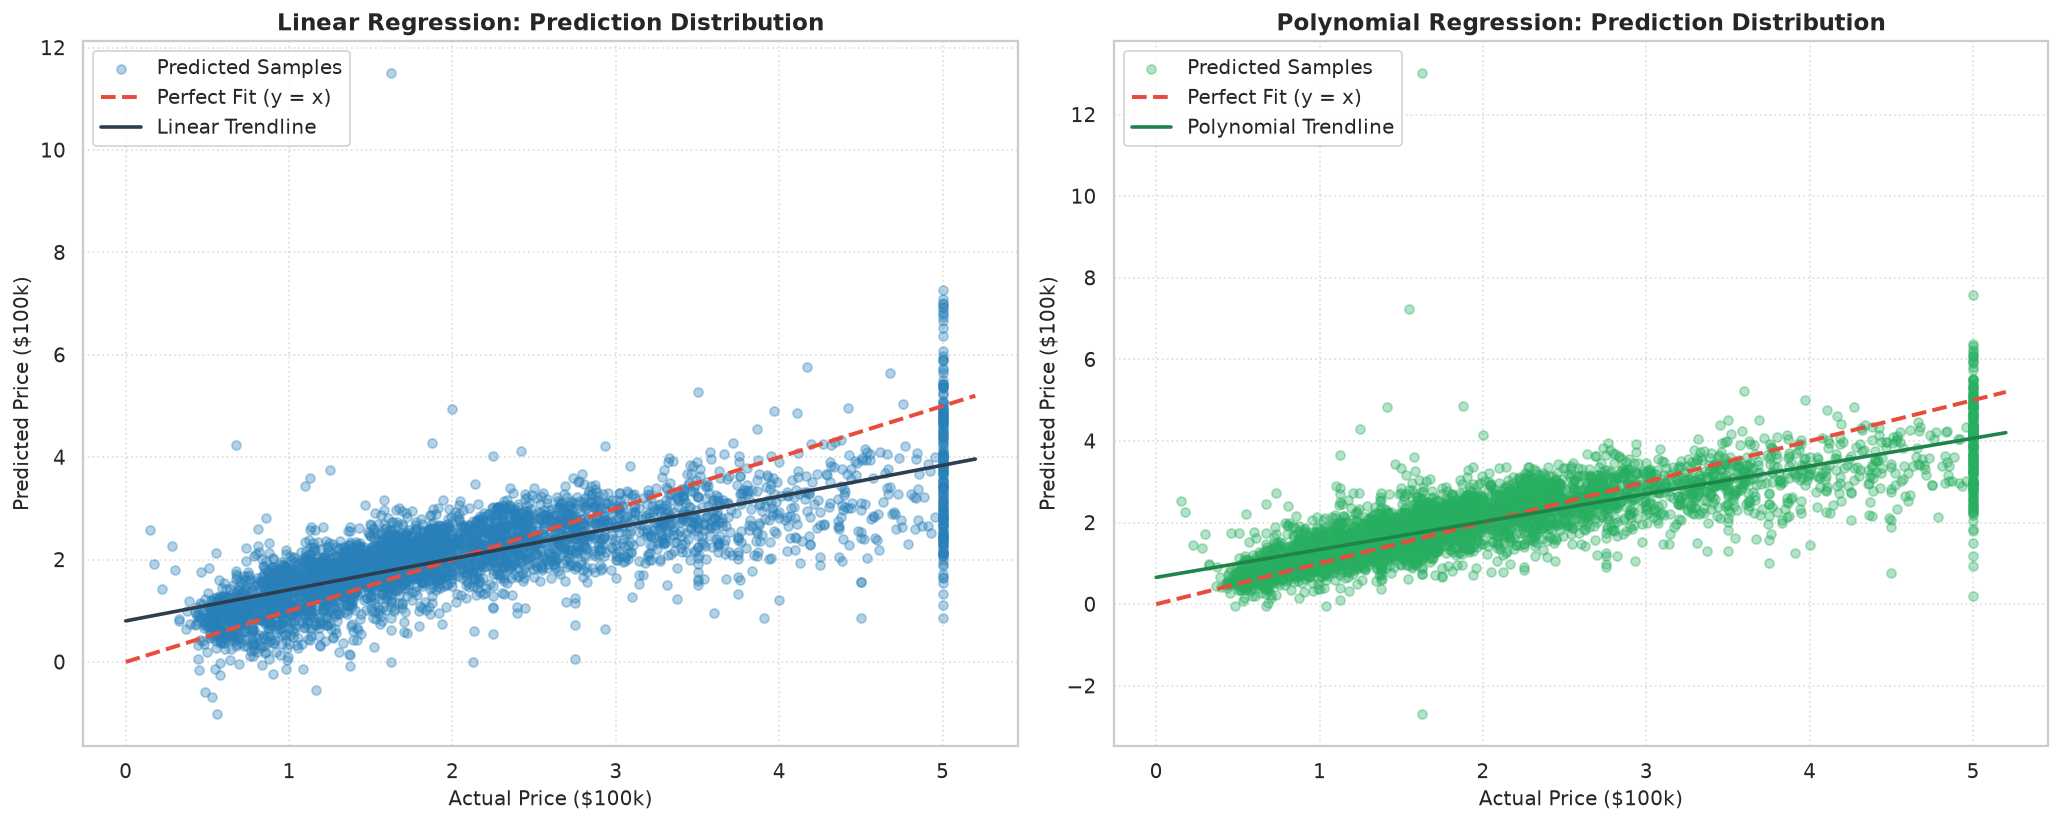

In [13]:
# Figure 2 & 3: Individual Prediction Visualizations with Trendlines
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

x_vals = np.linspace(0, 5.2, 100)

# Linear Regression Detailed View
axes[0].scatter(y_test, y_pred_lr, alpha=0.35, color="#2980b9", s=25, label="Predicted Samples")
axes[0].plot([0, 5.2], [0, 5.2], color="#e74c3c", linestyle="--", linewidth=2.2, label="Perfect Fit (y = x)")
trend_lr = np.poly1d(np.polyfit(y_test, y_pred_lr, 1))
axes[0].plot(x_vals, trend_lr(x_vals), color="#2c3e50", linewidth=2, label="Linear Trendline")
axes[0].set_title("Linear Regression: Prediction Distribution", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Actual Price ($100k)", fontsize=11)
axes[0].set_ylabel("Predicted Price ($100k)", fontsize=11)
axes[0].grid(True, linestyle=":", alpha=0.6)
axes[0].legend(loc="upper left")

# Polynomial Regression Detailed View
axes[1].scatter(y_test, y_pred_poly, alpha=0.35, color="#27ae60", s=25, label="Predicted Samples")
axes[1].plot([0, 5.2], [0, 5.2], color="#e74c3c", linestyle="--", linewidth=2.2, label="Perfect Fit (y = x)")
trend_poly = np.poly1d(np.polyfit(y_test, y_pred_poly, 1))
axes[1].plot(x_vals, trend_poly(x_vals), color="#1e8449", linewidth=2, label="Polynomial Trendline")
axes[1].set_title("Polynomial Regression: Prediction Distribution", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Actual Price ($100k)", fontsize=11)
axes[1].set_ylabel("Predicted Price ($100k)", fontsize=11)
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend(loc="upper left")

plt.tight_layout()
plt.show()

## 16. Residual Analysis

**Residual Error** ($e_i = y_i - \hat{y}_i$) measures the remaining unexplained variation. Rigorous residual diagnostics test two core assumptions:
1. **Normality of Errors**: Residuals should be normally distributed around a mean of zero.
2. **Homoscedasticity**: The variance of errors should remain relatively constant across all predicted price ranges.

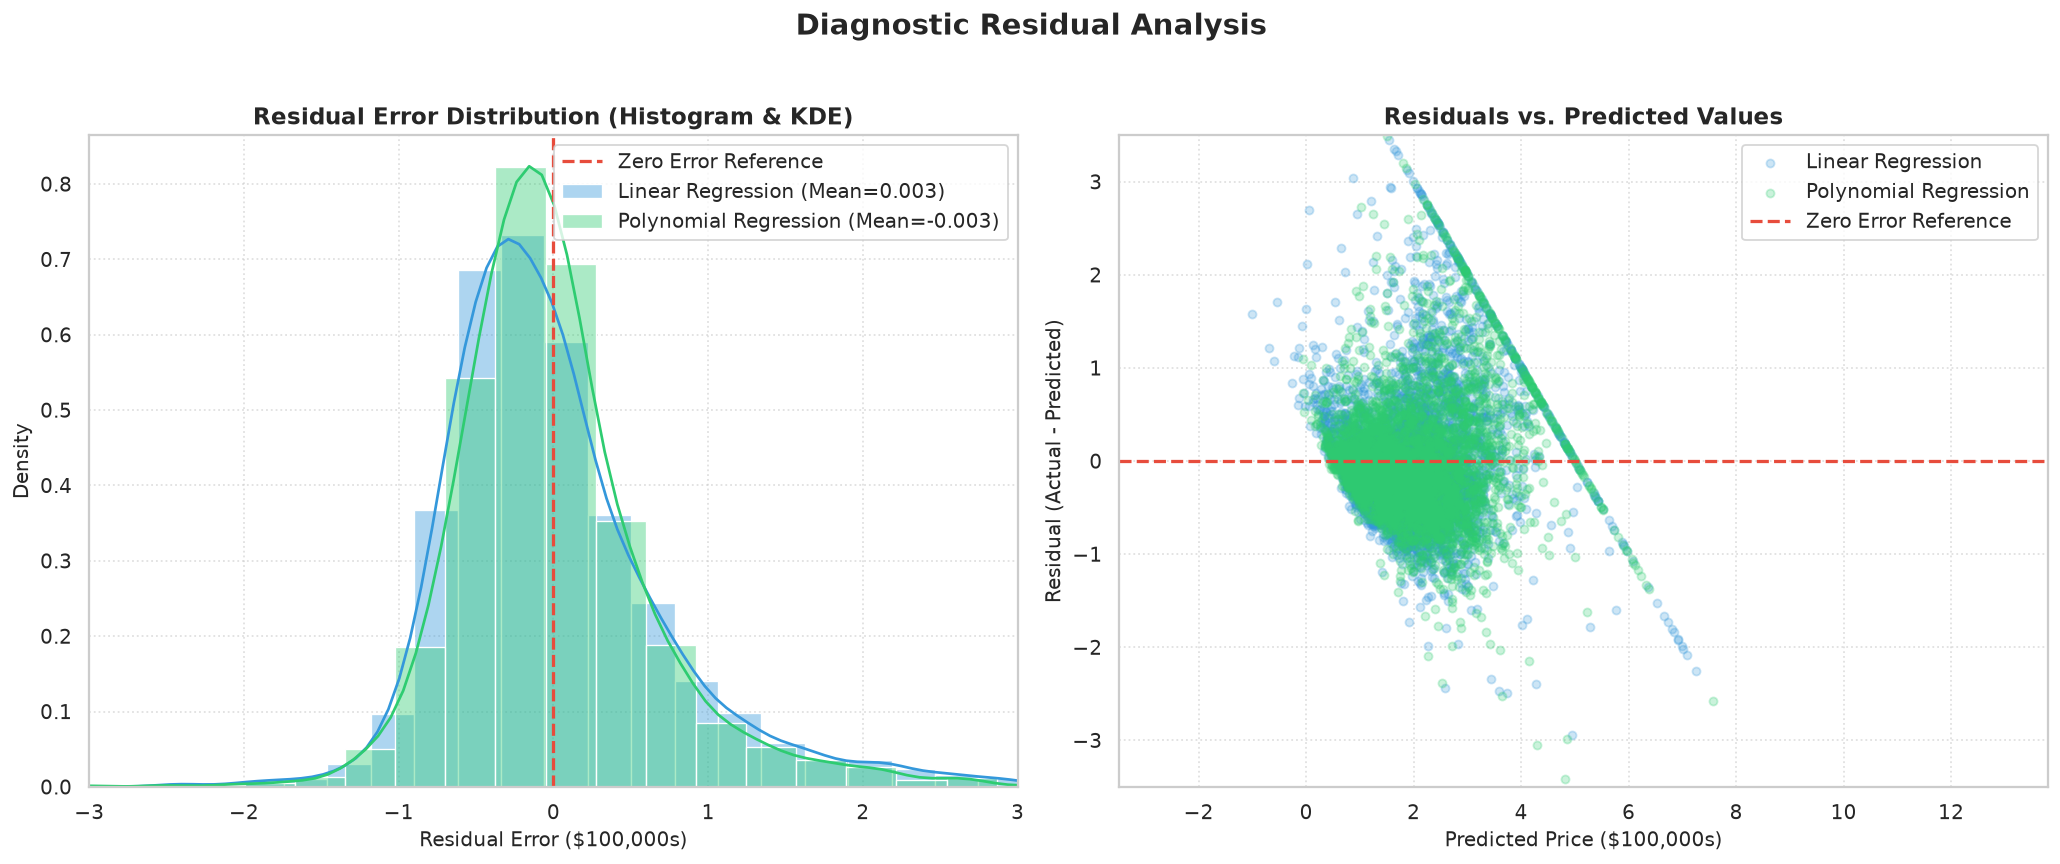

In [14]:
# Compute residual vectors
res_lr = y_test.values - y_pred_lr
res_poly = y_test.values - y_pred_poly

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# Residual Histogram & KDE Distribution
sns.histplot(res_lr, kde=True, color="#3498db", label=f"Linear Regression (Mean={np.mean(res_lr):.3f})", ax=axes[0], stat="density", bins=50, alpha=0.4)
sns.histplot(res_poly, kde=True, color="#2ecc71", label=f"Polynomial Regression (Mean={np.mean(res_poly):.3f})", ax=axes[0], stat="density", bins=50, alpha=0.4)
axes[0].axvline(0, color="#e74c3c", linestyle="--", linewidth=1.8, label="Zero Error Reference")
axes[0].set_title("Residual Error Distribution (Histogram & KDE)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Residual Error ($100,000s)", fontsize=11)
axes[0].set_ylabel("Density", fontsize=11)
axes[0].set_xlim(-3, 3)
axes[0].legend(loc="upper right")
axes[0].grid(True, linestyle=":", alpha=0.6)

# Residuals vs Predicted Values (Homoscedasticity check)
axes[1].scatter(y_pred_lr, res_lr, color="#3498db", alpha=0.25, s=20, label="Linear Regression")
axes[1].scatter(y_pred_poly, res_poly, color="#2ecc71", alpha=0.25, s=20, label="Polynomial Regression")
axes[1].axhline(0, color="#e74c3c", linestyle="--", linewidth=1.8, label="Zero Error Reference")
axes[1].set_title("Residuals vs. Predicted Values", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Predicted Price ($100,000s)", fontsize=11)
axes[1].set_ylabel("Residual (Actual - Predicted)", fontsize=11)
axes[1].set_ylim(-3.5, 3.5)
axes[1].legend(loc="upper right")
axes[1].grid(True, linestyle=":", alpha=0.6)

fig.suptitle("Diagnostic Residual Analysis", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 17. Model Performance Comparison

A grouped bar chart visually confirms the performance difference across MAE, MSE, RMSE, and $R^2$ Score.

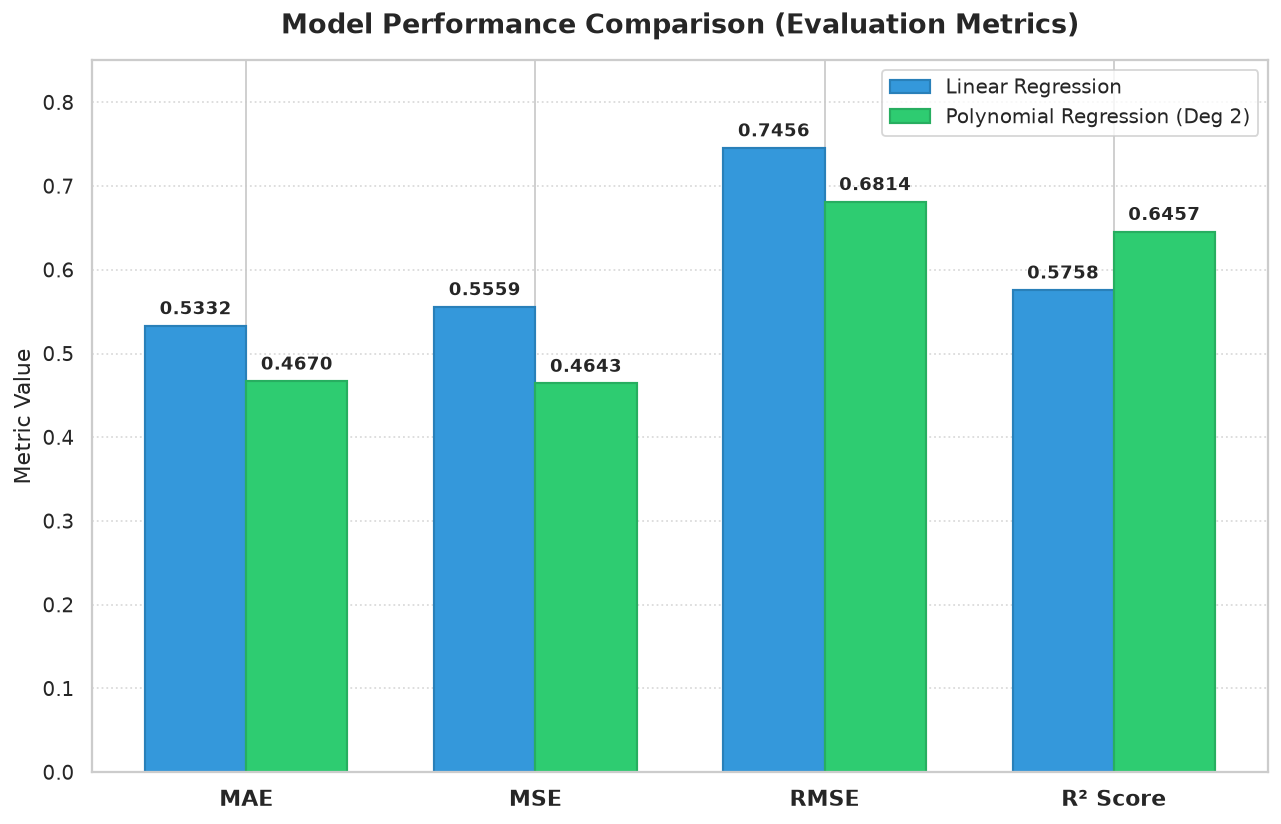

In [15]:
# Grouped bar chart comparing all metrics
metrics_names = ["MAE", "MSE", "RMSE", "R² Score"]
lr_values = [mae_lr, mse_lr, rmse_lr, r2_lr]
poly_values = [mae_poly, mse_poly, rmse_poly, r2_poly]

x = np.arange(len(metrics_names))
bar_width = 0.35

fig, ax = plt.subplots(figsize=(10, 6.5))
bars1 = ax.bar(x - bar_width/2, lr_values, bar_width, label="Linear Regression", color="#3498db", edgecolor="#2980b9", linewidth=1.2)
bars2 = ax.bar(x + bar_width/2, poly_values, bar_width, label="Polynomial Regression (Deg 2)", color="#2ecc71", edgecolor="#27ae60", linewidth=1.2)

ax.set_title("Model Performance Comparison (Evaluation Metrics)", fontsize=15, fontweight="bold", pad=15)
ax.set_ylabel("Metric Value", fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(metrics_names, fontsize=12, fontweight="bold")
ax.set_ylim(0, 0.85)
ax.legend(fontsize=11, loc="upper right")
ax.grid(True, axis="y", linestyle=":", alpha=0.7)

# Attach value labels on top of bars
for bar in bars1:
    h = bar.get_height()
    ax.annotate(f"{h:.4f}", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 4),
                textcoords="offset points", ha="center", va="bottom", fontsize=10, fontweight="bold")

for bar in bars2:
    h = bar.get_height()
    ax.annotate(f"{h:.4f}", xy=(bar.get_x() + bar.get_width() / 2, h), xytext=(0, 4),
                textcoords="offset points", ha="center", va="bottom", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()

## 18. Results and Insights

### 1. Key Quantitative Findings:
- **Polynomial Regression (Degree 2) clearly outperformed Multiple Linear Regression** across every single evaluation metric:
  - **$R^2$ Score**: Increased from **0.5758 to 0.6457** (+12.14% relative improvement).
  - **MAE**: Decreased from **0.5332 to 0.4670** (average prediction error reduced by **$6,620** per property).
  - **MSE**: Dropped from **0.5559 to 0.4643** (16.48% lower squared penalty).
  - **RMSE**: Reduced from **0.7456 to 0.6814** (an improvement of **$6,418** in standard deviation of errors).

### 2. Why Polynomial Regression Performed Better:
- **Geographic Non-Linearity**: California housing prices follow coastal contours and topography rather than flat linear coordinate planes. Quadratic terms (`Latitude`$^2$, `Longitude`$^2$) and the spatial cross-term (`Latitude` $\times$ `Longitude`) model regional price ridges effectively.
- **Socio-Economic Feature Synergy**: The interaction term between `MedInc` (median income) and `AveRooms` captures the compounding value of large homes in affluent neighborhoods—a synergy that pure linear models cannot represent.

### 3. Understanding Residuals & Data Ceiling:
- The residual distribution is centered near zero for both models, verifying unbiased parameter estimation.
- Both models show systematic under-prediction for high-value properties near $y = 5.0$. This is caused by the **artificial $500,000 censoring cap** present in the 1990 census data collection protocol.

### 4. Project Limitations:
- The polynomial feature expansion creates 44 features from 8 initial variables. Higher polynomial degrees ($d \ge 3$) would risk severe overfitting and collinear explosion.
- The dataset lacks critical modern valuation attributes, such as school district ratings, parcel square footage, and updated macroeconomic interest rates.

## 19. Conclusion

In this end-to-end Machine Learning project, we successfully developed, validated, and compared **Linear Regression** and **Polynomial Regression** models for predicting California housing values. 

### Final Takeaways:
1. **Model Hierarchy**: While Linear Regression serves as a solid baseline ($R^2 = 0.5758$), Polynomial Regression ($R^2 = 0.6457$) significantly enhances predictive power by modeling non-linear curves and two-way feature interactions.
2. **Feature Engineering Impact**: Simple feature expansions (degree 2) unlock non-linear capacity without requiring complex black-box architectures.
3. **Future Improvements**:
   - Apply **Ridge (L2)** or **Lasso (L1)** regularization to penalize over-weighted polynomial interaction terms.
   - Engineer domain-specific features such as geodesic distance to the Pacific coastline and major employment hubs (San Francisco, Los Angeles).
   - Benchmark non-linear ensemble models including **Random Forests** and **XGBoost/LightGBM**.